# ML with coordination descriptors: can a model predict surroundings it has never seen?

The question: with what surrounds the metal as input, can cheap descriptors predict stability and activity for a coordination environment
that was not in training? The data are the UMA results for 476 catalysts (28 metals × 17 supports).

- **Targets:**
  - E_f, stability. The formation energy vs bulk metal, calibrated to DFT. It gives U_diss = U° − E_f/n.
  - ΔG(*N₂→*NNH), the usual limiting step.
  - U_L(NRR), the best pathway.
  - ΔG*H, the HER descriptor.
- **Feature sets:**
  - **Metal only:** Z, period, group, Nd, χ_M, IE1, r_atom, E_coh. This is what the mid-sem models had.
  - **Metal + coordination:**
    - counts of N, S and C around the metal;
    - coordination number (3 or 4);
    - mean electronegativity and covalent radius of the neighbours;
    - χ_M − χ_site;
    - the arrangement of a 2+2 site (PEN, HEX, OPP), which the mid-sem features could not tell apart.
- **Validation, in increasing difficulty:**
  - random 5-fold;
  - **leave-one-support-out** (17 folds: an unseen surrounding);
  - **leave-one-family-out** (3 folds: an unseen family, e.g. train on S/N and N/C, predict single vacancies).
- **Models:** KRR, random forest, XGBoost. Settings are fixed or tuned inside each training fold, so the held-out data never chooses them.

In [1]:
import warnings; warnings.filterwarnings('ignore')
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.kernel_ridge import KernelRidge
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import KFold, LeaveOneGroupOut, GridSearchCV
from sklearn.metrics import mean_absolute_error, r2_score
from xgboost import XGBRegressor
import shap
pd.set_option('display.width', 200)
plt.rcParams.update({'font.size': 9, 'axes.spines.top': False, 'axes.spines.right': False})
df = pd.read_csv('UMA_476_full.csv').drop(columns=['U0_diss_V', 'n_e'], errors='ignore').merge(pd.read_csv('metal_descriptors.csv'), on='Metal')
df = df[df.status_bare == 'ok'].copy()
CHI = {'N': 3.04, 'S': 2.58, 'C': 2.55}; RCOV = {'N': 0.71, 'S': 1.05, 'C': 0.76}
df['chi_site'] = (df.n_N * CHI['N'] + df.n_S * CHI['S'] + df.n_C * CHI['C']) / df.CN
df['r_site'] = (df.n_N * RCOV['N'] + df.n_S * RCOV['S'] + df.n_C * RCOV['C']) / df.CN
df['EN_diff'] = df.chi_M - df.chi_site
for iso in ('PEN', 'HEX', 'OPP'):
    df[f'is_{iso}'] = df.Support.str.endswith(iso).astype(int)
METAL = ['Z', 'period', 'group', 'Nd', 'chi_M', 'IE1', 'r_atom', 'Ecoh']
COORD = ['n_N', 'n_S', 'n_C', 'CN', 'chi_site', 'r_site', 'EN_diff', 'is_PEN', 'is_HEX', 'is_OPP']
FEATS = {'metal only': METAL, 'metal + coordination': METAL + COORD}
okN = (df.status_N2_end == 'ok') & (df.status_NNH_end == 'ok')
TARGETS = {
    'Ef (eV)': df.Ef_cal.notna(),
    'ΔG *N2→*NNH (eV)': okN & df.dG_N2_to_NNH_end.notna(),
    'U_L NRR (V)': df.UL.notna(),
    'ΔG *H (eV)': (df.status_H == 'ok') & df['dG_H*'].notna(),
}
COL = {'Ef (eV)': 'Ef_cal', 'ΔG *N2→*NNH (eV)': 'dG_N2_to_NNH_end', 'U_L NRR (V)': 'UL', 'ΔG *H (eV)': 'dG_H*'}
for t, m in TARGETS.items(): print(f'{t:20s} n = {m.sum()}')

Ef (eV)              n = 459
ΔG *N2→*NNH (eV)     n = 337
U_L NRR (V)          n = 331
ΔG *H (eV)           n = 430


## Cross-validation

In [2]:
def models():
    return {
        'KRR': GridSearchCV(make_pipeline(StandardScaler(), KernelRidge(kernel='rbf')),
                            {'kernelridge__alpha': [0.01, 0.1, 1], 'kernelridge__gamma': [0.01, 0.03, 0.1]},
                            cv=KFold(4, shuffle=True, random_state=0), scoring='neg_mean_absolute_error'),
        'RF': RandomForestRegressor(n_estimators=300, min_samples_leaf=2, random_state=0, n_jobs=-1),
        'XGB': XGBRegressor(n_estimators=400, learning_rate=0.05, max_depth=4, subsample=0.8, colsample_bytree=0.8, random_state=0, n_jobs=2),
    }
SCHEMES = {'random 5-fold': None, 'leave-one-support-out': 'Support', 'leave-one-family-out': 'family'}

def oof(X, y, groups, model):
    p = np.full(len(y), np.nan)
    splits = KFold(5, shuffle=True, random_state=0).split(X) if groups is None else LeaveOneGroupOut().split(X, y, groups)
    for tr, te in splits:
        m = model(); m.fit(X[tr], y[tr]); p[te] = m.predict(X[te])
    return p

rows, PRED = [], {}
for t, mask in TARGETS.items():
    d = df[mask]; y = d[COL[t]].values
    for fs, cols in FEATS.items():
        X = d[cols].values.astype(float)
        for sch, gcol in SCHEMES.items():
            g = None if gcol is None else d[gcol].values
            for mn in models():
                p = oof(X, y, g, lambda mn=mn: models()[mn])
                PRED[(t, fs, sch, mn)] = p
                rows.append(dict(target=t, features=fs, scheme=sch, model=mn, n=len(y),
                                 MAE=mean_absolute_error(y, p), R2=r2_score(y, p), baseline_MAE=np.abs(y - y.mean()).mean()))
res = pd.DataFrame(rows)
best = res.loc[res.groupby(['target', 'features', 'scheme']).MAE.idxmin()]
tab = best.pivot_table(index=['target', 'scheme'], columns='features', values='MAE').round(3)
tab['gain from coordination'] = (tab['metal only'] - tab['metal + coordination']).round(3)
tab['guess-the-mean MAE'] = best.groupby(['target', 'scheme']).baseline_MAE.first().round(3)
print(tab.to_string())
res.round(4).to_csv('coord_ml_cv_results.csv', index=False)

features                                metal + coordination  metal only  gain from coordination  guess-the-mean MAE
target           scheme                                                                                             
Ef (eV)          leave-one-family-out                  1.347       1.690                   0.343               1.352
                 leave-one-support-out                 0.749       1.273                   0.524               1.352
                 random 5-fold                         0.291       1.237                   0.946               1.352
U_L NRR (V)      leave-one-family-out                  0.251       0.248                  -0.003               0.309
                 leave-one-support-out                 0.175       0.213                   0.038               0.309
                 random 5-fold                         0.178       0.220                   0.042               0.309
ΔG *H (eV)       leave-one-family-out                  0.453    

In [3]:
r2 = best.pivot_table(index=['target', 'scheme'], columns='features', values='R2').round(2)
print('R² of the best model in each cell:'); print(r2.to_string())
print('\nbest model per cell (metal + coordination):')
print(best[best.features == 'metal + coordination'][['target', 'scheme', 'model', 'MAE', 'R2']].round(3).to_string(index=False))

R² of the best model in each cell:
features                                metal + coordination  metal only
target           scheme                                                 
Ef (eV)          leave-one-family-out                   0.09       -0.41
                 leave-one-support-out                  0.70        0.19
                 random 5-fold                          0.94        0.22
U_L NRR (V)      leave-one-family-out                   0.32        0.33
                 leave-one-support-out                  0.55        0.47
                 random 5-fold                          0.56        0.44
ΔG *H (eV)       leave-one-family-out                   0.18        0.02
                 leave-one-support-out                  0.78        0.46
                 random 5-fold                          0.77        0.46
ΔG *N2→*NNH (eV) leave-one-family-out                   0.38        0.41
                 leave-one-support-out                  0.60        0.51
                

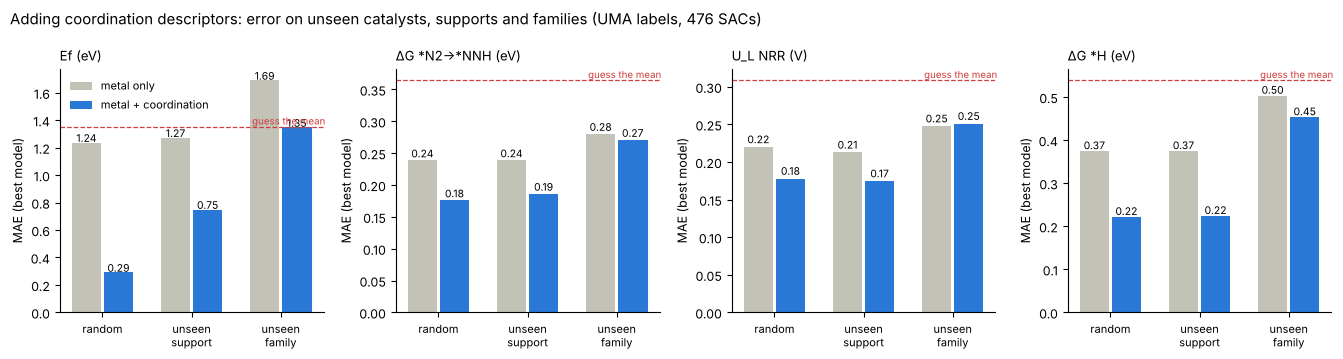

In [4]:
# figure: MAE by validation scheme, metal-only vs metal + coordination
fig, axes = plt.subplots(1, 4, figsize=(13.5, 3.6))
schemes = list(SCHEMES)
for ax, t in zip(axes, TARGETS):
    b = best[best.target == t]; x = np.arange(len(schemes)); w = 0.36
    for k, (fs, c) in enumerate((('metal only', '#c3c2b7'), ('metal + coordination', '#2a78d6'))):
        v = [b[(b.features == fs) & (b.scheme == s)].MAE.iloc[0] for s in schemes]
        ax.bar(x + (k - 0.5) * w, v, w * 0.92, color=c, label=fs)
        for xi, vi in zip(x, v): ax.text(xi + (k - 0.5) * w, vi + 0.005, f'{vi:.2f}', ha='center', fontsize=7.5)
    ax.axhline(b.baseline_MAE.iloc[0], color='#d03b3b', lw=0.9, ls='--')
    ax.text(len(schemes) - 0.5, b.baseline_MAE.iloc[0], 'guess the mean', fontsize=7, color='#d03b3b', ha='right', va='bottom')
    ax.set_xticks(x); ax.set_xticklabels(['random', 'unseen\nsupport', 'unseen\nfamily'], fontsize=8)
    ax.set_title(t, fontsize=9.5, loc='left'); ax.set_ylabel('MAE (best model)')
axes[0].legend(frameon=False, fontsize=8, loc='upper left')
fig.suptitle('Adding coordination descriptors: error on unseen catalysts, supports and families (UMA labels, 476 SACs)', x=0.01, ha='left')
fig.tight_layout(); fig.savefig('fig_coord_ml_mae.png', dpi=170); plt.show()

## Leave-one-family-out in detail
Each family in turn is predicted by a model trained only on the other two families. This is the hardest test: it asks whether the model can predict a whole new kind of site.

In [5]:
fam_rows = []
for t, mask in TARGETS.items():
    d = df[mask]; y = d[COL[t]].values
    for fs in FEATS:
        bm = best[(best.target == t) & (best.features == fs) & (best.scheme == 'leave-one-family-out')].model.iloc[0]
        p = PRED[(t, fs, 'leave-one-family-out', bm)]
        for f in d.family.unique():
            s = (d.family == f).values
            fam_rows.append(dict(target=t, features=fs, held_out=f, model=bm, n=s.sum(), MAE=np.abs(p[s] - y[s]).mean(),
                                 spearman=pd.Series(p[s]).corr(pd.Series(y[s]), method='spearman')))
fam = pd.DataFrame(fam_rows)
print(fam.pivot_table(index=['target', 'held_out'], columns='features', values=['MAE', 'spearman']).round(2).to_string())

                                                     MAE                        spearman           
features                            metal + coordination metal only metal + coordination metal only
target           held_out                                                                          
Ef (eV)          N/C double vacancy                 1.27       2.12                 0.42       0.59
                 S/N (Xu)                           1.25       1.74                 0.41       0.63
                 single vacancy                     1.65       0.92                 0.46       0.69
U_L NRR (V)      N/C double vacancy                 0.22       0.20                 0.73       0.62
                 S/N (Xu)                           0.31       0.30                 0.55       0.64
                 single vacancy                     0.22       0.25                 0.71       0.65
ΔG *H (eV)       N/C double vacancy                 0.37       0.44                 0.80       0.68


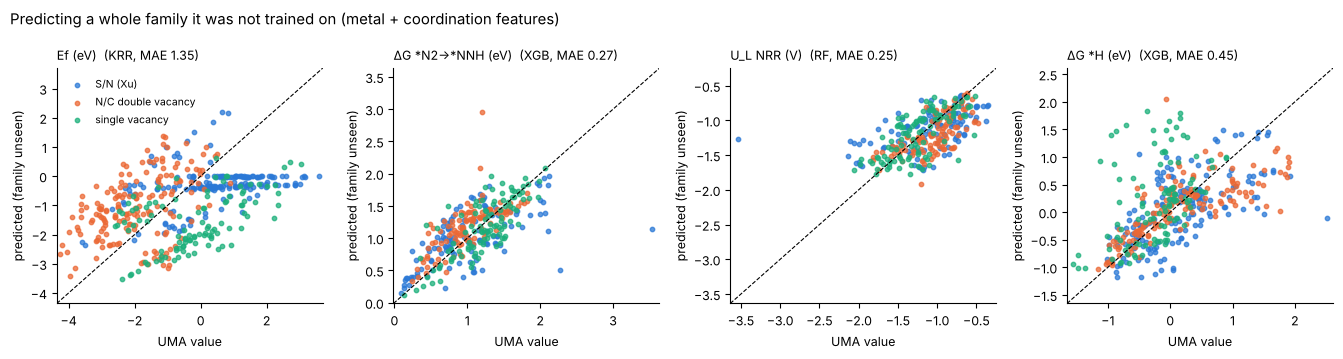

In [6]:
FAMC = {'S/N (Xu)': '#2a78d6', 'N/C double vacancy': '#eb6834', 'single vacancy': '#1baf7a'}
fig, axes = plt.subplots(1, 4, figsize=(13.5, 3.6))
for ax, t in zip(axes, TARGETS):
    d = df[TARGETS[t]]; y = d[COL[t]].values
    bm = best[(best.target == t) & (best.features == 'metal + coordination') & (best.scheme == 'leave-one-family-out')].model.iloc[0]
    p = PRED[(t, 'metal + coordination', 'leave-one-family-out', bm)]
    for f, c in FAMC.items():
        s = (d.family == f).values; ax.scatter(y[s], p[s], s=10, c=c, alpha=0.75, label=f)
    lo, hi = min(y.min(), p.min()) - 0.1, max(y.max(), p.max()) + 0.1
    ax.plot([lo, hi], [lo, hi], 'k--', lw=0.8); ax.set_xlim(lo, hi); ax.set_ylim(lo, hi)
    ax.set_xlabel('UMA value'); ax.set_ylabel('predicted (family unseen)')
    ax.set_title(f'{t}  ({bm}, MAE {np.abs(p - y).mean():.2f})', fontsize=9, loc='left')
axes[0].legend(frameon=False, fontsize=7.5)
fig.suptitle('Predicting a whole family it was not trained on (metal + coordination features)', x=0.01, ha='left')
fig.tight_layout(); fig.savefig('fig_coord_ml_family_parity.png', dpi=170); plt.show()

## Can the stage-1 verdict be predicted for an unseen family?
The predicted E_f goes through the same rule used in the screen: U_diss = U° − E_f/n, then the ±0.7 eV band.
Only stable and unstable calls are compared, because uncertain is not a verdict.

In [7]:
d = df[TARGETS['Ef (eV)']].copy()
def band(ef, u0, n):
    lo, hi = ef - 0.7, ef + 0.7
    return np.where((hi < 0) & (u0 - hi / n > 0), 'stable', np.where((lo > 0) | (u0 - lo / n < 0), 'unstable', 'uncertain'))
for fs in FEATS:
    bm = best[(best.target == 'Ef (eV)') & (best.features == fs) & (best.scheme == 'leave-one-family-out')].model.iloc[0]
    p = PRED[('Ef (eV)', fs, 'leave-one-family-out', bm)]
    pb = band(p, d.U0_diss_V.values, d.n_e.values); tb = d.stability.values
    conf = (pb != 'uncertain') & np.isin(tb, ['stable', 'unstable'])
    print(f'{fs:22s} confident calls {conf.sum()}, agree with UMA verdict {(pb[conf] == tb[conf]).mean():.0%};',
          'stable found:', int(((pb == 'stable') & (tb == 'stable')).sum()), 'of', int((tb == 'stable').sum()))

metal only             confident calls 228, agree with UMA verdict 68%; stable found: 12 of 97
metal + coordination   confident calls 192, agree with UMA verdict 89%; stable found: 41 of 97


## What drives the predictions (SHAP, XGBoost on all data, metal + coordination)

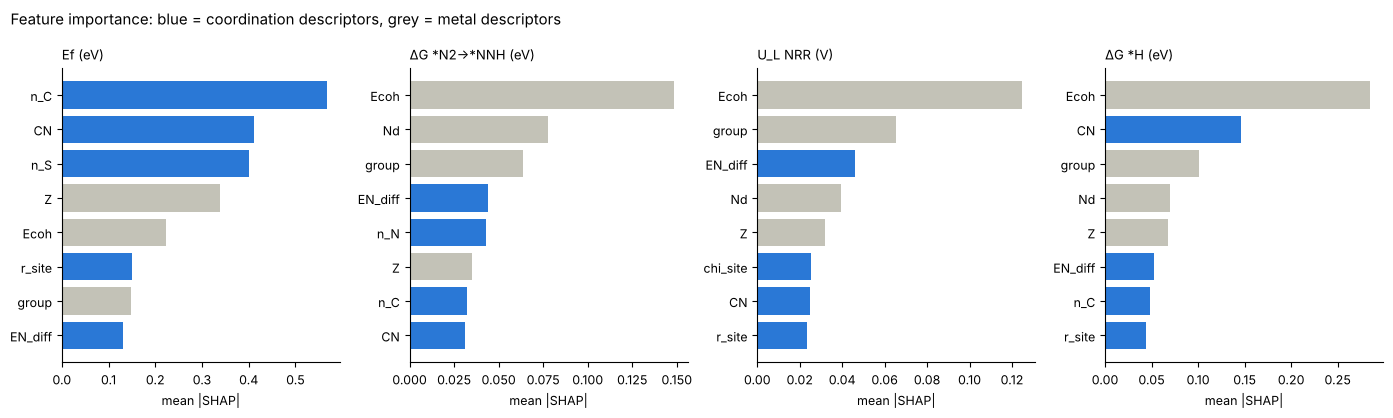

                                       Ef (eV)  ΔG *N2→*NNH (eV)  U_L NRR (V)  ΔG *H (eV)
share of importance from coordination     0.68              0.37         0.39        0.39


In [8]:
fig, axes = plt.subplots(1, 4, figsize=(14, 4.2))
imp = {}
for ax, t in zip(axes, TARGETS):
    d = df[TARGETS[t]]; X = d[METAL + COORD].astype(float); y = d[COL[t]].values
    m = models()['XGB']; m.fit(X.values, y)
    sv = shap.TreeExplainer(m).shap_values(X.values)
    s = pd.Series(np.abs(sv).mean(axis=0), index=X.columns).sort_values()
    imp[t] = s
    top = s.tail(8)
    ax.barh(top.index, top.values, color=['#2a78d6' if c in COORD else '#c3c2b7' for c in top.index])
    ax.set_title(t, fontsize=9.5, loc='left'); ax.set_xlabel('mean |SHAP|')
fig.suptitle('Feature importance: blue = coordination descriptors, grey = metal descriptors', x=0.01, ha='left')
fig.tight_layout(); fig.savefig('fig_coord_ml_shap.png', dpi=170); plt.show()
share = pd.DataFrame({t: [s[[c for c in s.index if c in COORD]].sum() / s.sum()] for t, s in imp.items()}, index=['share of importance from coordination']).round(2)
print(share.to_string())

In [9]:
best.round(4).to_csv('coord_ml_best.csv', index=False); fam.round(4).to_csv('coord_ml_family_holdout.csv', index=False)
print('saved coord_ml_cv_results.csv, coord_ml_best.csv, coord_ml_family_holdout.csv and 3 figures')

saved coord_ml_cv_results.csv, coord_ml_best.csv, coord_ml_family_holdout.csv and 3 figures
